# 03 — Data Modelling
## OSMI 2016: Workplace Support, Psychological Safety, and Disclosure Climate

### Objective
Fit and compare four pre-specified unsupervised clustering families on the 1,131-respondent eligible cohort defined in Notebook 01: **K-Modes**, **MCA + K-Means**, **average-linkage agglomerative clustering**, and **HDBSCAN**.

This notebook consumes the persisted outputs of Notebook 02. It does not redefine the cohort, change the 15 primary features, or use demographic, health-history, diagnosis, treatment, geographic, or free-text variables as clustering inputs.

### Modelling contract (aligned with Notebook 01)
| Family | Representation | Native diagnostics (Notebook 01 specification) |
|---|---|---|
| K-Modes | Categorical labels, simple-matching dissimilarity | Cost; repeated-run **and resampling** stability |
| MCA + K-Means | Row principal coordinates of the complete disjunctive matrix | MCA-space silhouette, Davies–Bouldin, Calinski–Harabasz |
| Agglomerative | Precomputed domain-balanced Gower dissimilarity, **average linkage** (Ward is invalid for arbitrary dissimilarities) | Gower silhouette; cophenetic correlation (dendrogram fidelity only) |
| HDBSCAN | Same precomputed Gower dissimilarity | **DBCV**, noise share, cluster persistence, membership strength |

- A common Gower silhouette is a *supplementary* cross-family diagnostic, not a universal ranking criterion.
- Repeated-start ARI measures optimisation stability; the subsample ARI for K-Modes measures resampling stability. Neither is population stability.
- One representative configuration is selected **within each family** under explicit admissibility rules. Final family selection is deferred to Notebook 04.

The data are historical, voluntary and self-reported. Clusters describe aggregate workplace-response patterns; they are not clinical labels or employee-risk classifications.

### Audit of the previous version and corrections applied
The earlier version of this notebook was reviewed against Notebook 01 and against its own saved outputs. The corrections below are implemented in this version.

| # | Issue found | Why it matters | Correction |
|---|---|---|---|
| 1 | HDBSCAN text claimed scikit-learn and "DBCV/persistence unavailable"; the code imported the `hdbscan` package and computed both; metadata recorded `dbcv_available: False`. | Documentation contradicted the implementation. | Single, documented implementation (`hdbscan` package); metadata and text now agree and record package versions. |
| 2 | HDBSCAN configurations were ranked by a Gower silhouette on non-noise points. The saved run ranked a configuration with 87% noise "best" (silhouette 0.52 on 13% of respondents). | Notebook 01 specifies DBCV, noise share, persistence and membership strength; a silhouette on a small non-noise remnant is not a valid density-based criterion. | Admissibility (≥ 2 clusters, ≥ 50% coverage, DBCV > 0) then DBCV ranking. |
| 3 | DBCV used `d = len(feature_metadata)` (rows of a metadata table). | `d` is the dimensionality entering the DBCV core-distance formula. | `d` = number of primary clustering features (15). |
| 4 | HDBSCAN grid (`min_cluster_size` ≥ 15, `min_samples` ≥ 5, EOM only) labelled 100% of respondents as noise in 8 of 12 runs. | The grid could not reveal whether any density structure exists. | Grid widened (smaller `min_samples`/`min_cluster_size`, EOM and leaf selection). |
| 5 | Agglomerative representative contained a **2-respondent cluster** (largest cluster 1,129). The "cluster-size safeguard" existed only as prose. | A silhouette-maximising partition with a 2-person cluster is not a usable segmentation. | Minimum cluster size enforced in selection; average linkage remains primary, with complete and weighted linkage as clearly labelled sensitivity fallbacks. |
| 6 | K-Modes used `n_init=1` per fit; mean ARI was 0.22–0.29, and k = 4 was chosen on an ARI margin of 0.0009. | Single-start K-Modes is dominated by local optima; the selection was noise-driven. Notebook 01 also requires resampling stability. | Each repeat is a best-of-`n_init` fit; stability floor + silhouette ranking; subsample (80%) resampling ARI added; cost elbow reported. |
| 7 | Run metadata described K-Modes as "transparent simple-matching… random row initialization", but the code used the `kmodes` package with Huang initialisation. | Misreported method. | Metadata describes the actual implementation. |
| 8 | MCA retention rule was documented as "reach 80% raw inertia", but the cap of 20 truncated it at 74%. Raw inertia percentages are known to be pessimistic in MCA. | Rule not actually applied; arbitrary dimensionality for K-Means. | Retain dimensions with eigenvalue > 1/Q (standard MCA criterion); Benzécri-adjusted inertia reported; weighted-coordinate identity asserted. |
| 9 | Silhouettes used a 600-row sample. | Unnecessary at N = 1,131 and can omit small clusters. | Full-sample silhouettes. |
| 10 | The "excluded variables" assertion on the MCA matrix was vacuous (its columns are category indicators, not variable names); the row-sum check did not prove one active category *per feature*. | Weak validation of the input contract. | Indicator columns mapped to features; exactly one active indicator per feature per respondent asserted; Notebook 01 domain spec asserted. |
| 11 | Agglomerative labels were 1-based while other families were 0-based; exported labels had no source-row key; handoff stored absolute local paths. | Inconsistent downstream joins; non-portable outputs. | Labels harmonised (0-based, noise = −1); `row_mapping` merged into exports; relative paths. |

## 1. Imports, configuration and project paths

In [2]:
from __future__ import annotations

import json
import math
import platform
import warnings
from importlib import metadata as importlib_metadata
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from hdbscan import HDBSCAN
from hdbscan.validity import validity_index
from IPython.display import display
from kmodes.kmodes import KModes
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

# ----------------------------------------------------------------------------
# Modelling configuration (every threshold used for selection is declared here)
# ----------------------------------------------------------------------------
RANDOM_STATE = 42
K_VALUES = list(range(2, 9))          # candidate k for K-Modes, MCA + K-Means, Agglomerative

# Repeated-start stability
N_REPEATS = 10                        # independent repeats per k
KMODES_N_INIT = 5                     # Huang starts per K-Modes fit (lowest cost kept)

# K-Modes resampling stability (Notebook 01: "repeated-run/resampling stability")
N_RESAMPLES = 20
SUBSAMPLE_FRACTION = 0.80

# Admissibility screens (screening thresholds, not universal truths)
MIN_CLUSTER_SHARE = 0.05              # a usable segment holds >= 5% of respondents
STABILITY_FLOOR = 0.50                # mean pairwise ARI regarded as "stable enough" to rank first
MIN_COVERAGE = 0.50                   # HDBSCAN: at least half of respondents must be clustered
DBCV_FLOOR = 0.0                      # HDBSCAN: DBCV <= 0 means no density structure beyond chance

# Agglomerative linkage: average is the Notebook 01 primary; the others are sensitivity fallbacks
LINKAGES = {"average": "primary", "weighted": "sensitivity", "complete": "sensitivity"}

# HDBSCAN grid
HDBSCAN_MIN_CLUSTER_SIZES = [10, 15, 25, 40, 60]
HDBSCAN_MIN_SAMPLES = [1, 3, 5, 10]
HDBSCAN_SELECTION_METHODS = ["eom", "leaf"]

# Resolve the project root whether this notebook is opened from the repository
# root or from its notebooks/ directory.
HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent if HERE.name == "notebooks" else HERE
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results" / "data_modelling"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "data_modelling"
for directory in (RESULTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

PACKAGE_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "kmodes": importlib_metadata.version("kmodes"),
    "hdbscan": importlib_metadata.version("hdbscan"),
}
print(json.dumps(PACKAGE_VERSIONS, indent=2))

{
  "python": "3.13.7",
  "numpy": "2.5.4",
  "pandas": "3.1.0",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "kmodes": "0.12.2",
  "hdbscan": "0.8.44"
}


## 2. Load Notebook 02 artefacts and validate the input contract

Validation covers (i) shapes and keys, (ii) the **Notebook 01 feature and domain specification**, (iii) the Gower matrix properties required by the hierarchical and density-based methods, (iv) the MCA indicator structure *per feature*, and (v) the absence of excluded variables. Where a check concerns consistency between two representations of the same data, a mismatch raises a warning with a diagnostic table rather than silently proceeding.

In [3]:
INPUT_FILES = {
    "kmodes": PROCESSED_DIR / "osmi_2016_kmodes_input.csv",
    "mca_indicator": PROCESSED_DIR / "osmi_2016_mca_indicator_matrix.csv",
    "gower_typed": PROCESSED_DIR / "osmi_2016_gower_typed_input.csv",
    "gower": PROCESSED_DIR / "osmi_2016_gower_dissimilarity.npy",
    "row_mapping": PROCESSED_DIR / "osmi_2016_model_row_mapping.csv",
    "feature_metadata": PROCESSED_DIR / "osmi_2016_feature_metadata.csv",
    "preparation_metadata": PROCESSED_DIR / "osmi_2016_preparation_metadata.json",
}
missing_files = [str(path) for path in INPUT_FILES.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Notebook 02 artefacts are missing. Run Notebook 02 first. Missing: "
        + ", ".join(missing_files)
    )

X_kmodes = pd.read_csv(INPUT_FILES["kmodes"], dtype="string")
X_mca_indicator = pd.read_csv(INPUT_FILES["mca_indicator"])
X_gower_typed = pd.read_csv(INPUT_FILES["gower_typed"], dtype="string")
D_gower = np.load(INPUT_FILES["gower"], allow_pickle=False)
row_mapping = pd.read_csv(INPUT_FILES["row_mapping"])
feature_metadata = pd.read_csv(INPUT_FILES["feature_metadata"])

with INPUT_FILES["preparation_metadata"].open(encoding="utf-8") as file:
    preparation_metadata = json.load(file)

PRIMARY_FEATURES = preparation_metadata["primary_features"]
FEATURES_BY_DOMAIN = preparation_metadata["feature_domains"]
EXPECTED_N = int(preparation_metadata["eligible_cohort_size"])
EXPECTED_P = int(preparation_metadata["primary_feature_count"])

# --- Notebook 01 specification (cohort size, feature count, domain membership) ---
NB01_FEATURES_BY_DOMAIN = {
    "employer_support": [
        "mh_benefits", "mh_formal_discussion", "mh_resources_offered",
        "mh_anonymity_protected", "mh_medical_leave_ease", "mh_vs_ph_seriousness",
    ],
    "psychological_safety": [
        "mh_discussion_consequences", "ph_discussion_consequences",
        "mh_comfort_coworkers", "mh_comfort_supervisor", "observed_mh_consequences",
    ],
    "disclosure_career_climate": [
        "interview_ph_reveal", "interview_mh_reveal",
        "mh_hurt_career", "coworker_negative_view",
    ],
}
NB01_EXPECTED_N = 1131
assert EXPECTED_N == NB01_EXPECTED_N, f"Notebook 01 specifies {NB01_EXPECTED_N} respondents; found {EXPECTED_N}."
assert EXPECTED_P == 15 and len(PRIMARY_FEATURES) == 15
assert {d: set(v) for d, v in FEATURES_BY_DOMAIN.items()} == \
       {d: set(v) for d, v in NB01_FEATURES_BY_DOMAIN.items()}, \
       "Feature/domain assignment differs from the Notebook 01 specification."
assert set(PRIMARY_FEATURES) == {f for v in NB01_FEATURES_BY_DOMAIN.values() for f in v}

# --- Shapes, keys, and missing values ---
assert X_kmodes.shape == (EXPECTED_N, EXPECTED_P)
assert X_gower_typed.shape == (EXPECTED_N, EXPECTED_P)
assert list(X_kmodes.columns) == PRIMARY_FEATURES
assert list(X_gower_typed.columns) == PRIMARY_FEATURES
assert X_mca_indicator.shape[0] == EXPECTED_N
assert len(row_mapping) == EXPECTED_N
assert row_mapping["model_row_index"].is_unique
assert np.array_equal(row_mapping["model_row_index"].to_numpy(), np.arange(EXPECTED_N))
assert not X_kmodes.isna().any().any()
assert not X_gower_typed.isna().any().any()
assert not X_mca_indicator.isna().any().any()

# --- Gower dissimilarity: required properties for precomputed use ---
D_gower = np.asarray(D_gower, dtype=np.float64)
assert D_gower.shape == (EXPECTED_N, EXPECTED_N)
assert np.isfinite(D_gower).all()
assert np.allclose(D_gower, D_gower.T, atol=1e-6)
assert np.allclose(np.diag(D_gower), 0.0, atol=1e-6)
assert D_gower.min() >= -1e-6 and D_gower.max() <= 1 + 1e-6
# Remove float32 round-off so SciPy/HDBSCAN see an exactly symmetric, zero-diagonal matrix in [0, 1].
D_gower = np.clip((D_gower + D_gower.T) / 2.0, 0.0, 1.0)
np.fill_diagonal(D_gower, 0.0)

# --- MCA indicator matrix: map every column to exactly one primary feature ---
def map_indicator_columns(columns, features) -> pd.Series:
    """Longest-prefix match of each indicator column to a primary feature."""
    mapping = {}
    for col in columns:
        matches = [f for f in features if str(col).startswith(f)]
        if not matches:
            raise ValueError(
                f"Indicator column '{col}' does not belong to any primary feature "
                "(an excluded or unknown variable may have leaked into the MCA input)."
            )
        mapping[col] = max(matches, key=len)
    return pd.Series(mapping, name="feature")

indicator_feature = map_indicator_columns(X_mca_indicator.columns, PRIMARY_FEATURES)
Z_check = X_mca_indicator.to_numpy(dtype=np.float64)
if not np.isin(Z_check, [0.0, 1.0]).all():
    raise ValueError("MCA indicator matrix must contain only 0/1 values.")

category_check = []
for feature in PRIMARY_FEATURES:
    cols = indicator_feature.index[indicator_feature == feature]
    if len(cols) < 2:
        raise ValueError(f"Feature '{feature}' has fewer than two indicator columns.")
    if not (X_mca_indicator[cols].sum(axis=1) == 1).all():
        raise ValueError(f"Feature '{feature}': each respondent needs exactly one active indicator.")
    category_check.append({
        "feature": feature,
        "indicator_columns": len(cols),
        "categories_in_kmodes_input": int(X_kmodes[feature].nunique()),
        "categories_in_gower_input": int(X_gower_typed[feature].nunique()),
    })
category_check = pd.DataFrame(category_check)
inconsistent = category_check[
    (category_check["indicator_columns"] != category_check["categories_in_kmodes_input"])
    | (category_check["indicator_columns"] != category_check["categories_in_gower_input"])
]
if not inconsistent.empty:
    warnings.warn("Category counts differ between model inputs; review Notebook 02 outputs.")
    display(inconsistent)

# --- Excluded variables must not appear in the label-based inputs ---
EXCLUDED = {
    "gender", "age", "country_live", "country_work", "us_state_live", "us_state_work",
    "company_size", "work_remote", "self_employed", "tech_company", "tech_role",
    "source_row_position",
}
for name, matrix in {"kmodes": X_kmodes, "gower_typed": X_gower_typed}.items():
    leaked = EXCLUDED.intersection(matrix.columns)
    assert not leaked, f"Excluded variables present in {name} input: {sorted(leaked)}"

# Minimum admissible cluster size, derived once from the cohort size.
MIN_CLUSTER_SIZE = int(math.ceil(MIN_CLUSTER_SHARE * EXPECTED_N))

domain_summary = pd.DataFrame({
    "domain": list(FEATURES_BY_DOMAIN),
    "features": [len(v) for v in FEATURES_BY_DOMAIN.values()],
    "domain_weight": [1 / len(FEATURES_BY_DOMAIN)] * len(FEATURES_BY_DOMAIN),
})
display(domain_summary)
display(category_check)
print(f"Validated {EXPECTED_N:,} respondents × {EXPECTED_P} primary features.")
print(f"Gower matrix: {D_gower.shape}, range=[{D_gower.min():.3f}, {D_gower.max():.3f}]; "
      f"MCA indicator columns: {X_mca_indicator.shape[1]}")
print(f"Minimum admissible cluster size: {MIN_CLUSTER_SIZE} respondents ({MIN_CLUSTER_SHARE:.0%} of the cohort).")

,domain,features,domain_weight
0,employer_support,6,0.333333
1,psychological_safety,5,0.333333
2,disclosure_career_climate,4,0.333333


,feature,indicator_columns,categories_in_kmodes_input,categories_in_gower_input
0,mh_benefits,4,4,4
1,mh_formal_discussion,3,3,3
2,mh_resources_offered,3,3,3
3,mh_anonymity_protected,3,3,3
4,mh_medical_leave_ease,6,6,6
5,mh_vs_ph_seriousness,3,3,3
6,mh_discussion_consequences,3,3,3
7,ph_discussion_consequences,3,3,3
8,mh_comfort_coworkers,3,3,3
9,mh_comfort_supervisor,3,3,3


Validated 1,131 respondents × 15 primary features.
Gower matrix: (1131, 1131), range=[0.000, 1.000]; MCA indicator columns: 52
Minimum admissible cluster size: 57 respondents (5% of the cohort).


## 3. Shared evaluation functions

All silhouettes use **every** eligible respondent (no subsampling): at N = 1,131 the full precomputed silhouette is cheap, and sampling can drop small clusters. For HDBSCAN, noise (label −1) is excluded from the silhouette but is always retained in coverage and noise reporting. A silhouette is undefined with fewer than two clusters, or when every evaluated respondent is its own cluster; such cases are recorded as missing rather than coerced.

Cluster labels are harmonised across families: clusters are numbered `0…k−1` and noise is `−1`.

In [4]:
def relabel_contiguous(labels: np.ndarray) -> np.ndarray:
    """Map non-noise labels to 0..k-1 (ordered by original label); keep noise as -1."""
    labels = np.asarray(labels)
    out = np.full(labels.shape, -1, dtype=np.int32)
    for new, old in enumerate(np.unique(labels[labels != -1])):
        out[labels == old] = new
    return out


def cluster_summary(labels: np.ndarray) -> dict:
    labels = np.asarray(labels)
    non_noise = labels != -1
    assigned = labels[non_noise]
    counts = pd.Series(assigned).value_counts()
    return {
        "n_clusters": int(counts.size),
        "n_noise": int((~non_noise).sum()),
        "noise_share": float((~non_noise).mean()),
        "coverage": float(non_noise.mean()),
        "smallest_cluster_size": int(counts.min()) if len(counts) else 0,
        "median_cluster_size": float(counts.median()) if len(counts) else 0.0,
        "max_cluster_size": int(counts.max()) if len(counts) else 0,
    }


def gower_silhouette(labels: np.ndarray) -> float:
    """Silhouette on the precomputed Gower matrix, all non-noise respondents."""
    labels = np.asarray(labels)
    idx = np.flatnonzero(labels != -1)
    if idx.size < 3:
        return np.nan
    y = labels[idx]
    n_labels = np.unique(y).size
    if n_labels < 2 or n_labels >= idx.size:
        return np.nan
    return float(silhouette_score(D_gower[np.ix_(idx, idx)], y, metric="precomputed"))


def mca_silhouette(coordinates: np.ndarray, labels: np.ndarray) -> float:
    labels = np.asarray(labels)
    n_labels = np.unique(labels).size
    if n_labels < 2 or n_labels >= len(labels):
        return np.nan
    return float(silhouette_score(coordinates, labels, metric="euclidean"))


def pairwise_mean_ari(label_runs: list[np.ndarray]) -> float:
    if len(label_runs) < 2:
        return np.nan
    return float(np.mean([adjusted_rand_score(a, b) for a, b in combinations(label_runs, 2)]))


def elbow_k(ks, values) -> int:
    """Elbow of a decreasing curve: k with the largest gap below the chord joining its end points."""
    ks = np.asarray(ks, dtype=float)
    values = np.asarray(values, dtype=float)
    if np.ptp(ks) == 0 or np.ptp(values) == 0:
        return int(ks[0])
    x = (ks - ks.min()) / np.ptp(ks)
    y = (values - values.min()) / np.ptp(values)
    chord = y[0] + (y[-1] - y[0]) * x
    return int(ks[np.argmax(chord - y)])

## 4. MCA: row principal coordinates

Multiple correspondence analysis is computed from the complete disjunctive matrix **Z** (respondents × category indicators) with *Q = 15* active variables. With correspondence matrix **P = Z / (nQ)**, row masses **r** and column masses **c**, the standardised residuals are **S = D_r^{-1/2}(P − rcᵀ)D_c^{-1/2}**. The SVD **S = UΣVᵀ** gives eigenvalues λ = σ² and row principal coordinates **F = D_r^{-1/2} U Σ**. Euclidean distance between rows of **F** reproduces the χ² distance between respondent response profiles, which is why K-Means on **F** is appropriate.

**Dimension retention.** MCA has at most *q − Q* non-trivial dimensions (q = number of indicator columns). The standard criterion retains dimensions with **λ > 1/Q** (above-average inertia). Raw inertia percentages are known to understate the quality of an MCA solution, so Benzécri/Greenacre-adjusted inertia rates are also reported. As in Notebook 01, categories are treated nominally; ordinal spacing is not retained in this representation.

In [5]:
Z = X_mca_indicator.to_numpy(dtype=np.float64)
n, q = Z.shape
Q = EXPECTED_P

P = Z / (n * Q)
row_masses = P.sum(axis=1)
column_masses = P.sum(axis=0)
if np.any(row_masses <= 0) or np.any(column_masses <= 0):
    raise ValueError("MCA contains zero-mass rows or columns.")

standardised_residuals = (
    (P - np.outer(row_masses, column_masses))
    / np.sqrt(row_masses[:, None] * column_masses[None, :])
)
U, singular_values, Vt = np.linalg.svd(standardised_residuals, full_matrices=False)

# Only the first q - Q dimensions are non-trivial; the remainder are numerically zero.
n_nontrivial = q - Q
singular_values = singular_values[:n_nontrivial]
U = U[:, :n_nontrivial]
eigenvalues = singular_values ** 2
total_inertia = float(eigenvalues.sum())
assert np.isclose(total_inertia, (q - Q) / Q, rtol=1e-6), "Total MCA inertia must equal (q - Q) / Q."

explained_inertia = eigenvalues / total_inertia
cumulative_inertia = np.cumsum(explained_inertia)

# Benzécri-adjusted eigenvalues (only dimensions with eigenvalue > 1/Q contribute), expressed as a
# share of Greenacre's adjusted total inertia, so rates are not trivially normalised to 100%.
benzecri = np.where(eigenvalues > 1 / Q, ((Q / (Q - 1)) * (eigenvalues - 1 / Q)) ** 2, 0.0)
greenacre_total = (Q / (Q - 1)) * (np.sum(eigenvalues ** 2) - (q - Q) / Q ** 2)
benzecri_rate = benzecri / greenacre_total

# Retain dimensions with above-average inertia (eigenvalue > 1/Q), at least 2.
n_components = max(int(np.sum(eigenvalues > 1 / Q)), 2)
mca_coordinates = (
    U[:, :n_components] * singular_values[:n_components][None, :] / np.sqrt(row_masses[:, None])
)

# Identity check: weighted squared principal coordinates reproduce each eigenvalue.
assert np.allclose(
    (row_masses[:, None] * mca_coordinates ** 2).sum(axis=0), eigenvalues[:n_components]
), "Row principal coordinates are inconsistent with the MCA eigenvalues."

mca_inertia = pd.DataFrame({
    "dimension": np.arange(1, len(eigenvalues) + 1),
    "eigenvalue": eigenvalues,
    "explained_inertia_pct": explained_inertia * 100,
    "cumulative_inertia_pct": cumulative_inertia * 100,
    "adjusted_inertia_pct": benzecri_rate * 100,
    "retained": np.arange(len(eigenvalues)) < n_components,
})

display(mca_inertia.head(max(n_components + 3, 15)))
print(
    f"MCA indicator matrix: {Z.shape}; non-trivial dimensions: {n_nontrivial}; "
    f"retained (eigenvalue > 1/Q = {1 / Q:.4f}): {n_components}; "
    f"cumulative raw inertia: {cumulative_inertia[n_components - 1]:.1%}; "
    f"cumulative adjusted inertia (Greenacre): {benzecri_rate[:n_components].sum():.1%}"
)

,dimension,eigenvalue,explained_inertia_pct,cumulative_inertia_pct,adjusted_inertia_pct,retained
0,1,0.306666,12.432389,12.432389,69.919453,True
1,2,0.153157,6.209063,18.641452,9.080577,True
2,3,0.122313,4.958635,23.600087,3.758828,True
3,4,0.103119,4.180497,27.780583,1.612977,True
4,5,0.096852,3.926416,31.706999,1.106011,True
5,6,0.091296,3.701188,35.408187,0.736349,True
6,7,0.085913,3.482950,38.891138,0.449640,True
7,8,0.084342,3.419278,42.310416,0.379249,True
8,9,0.076793,3.113238,45.423653,0.124480,True
9,10,0.075810,3.073371,48.497025,0.101478,True


MCA indicator matrix: (1131, 52); non-trivial dimensions: 37; retained (eigenvalue > 1/Q = 0.0667): 14; cumulative raw inertia: 59.6%; cumulative adjusted inertia (Greenacre): 87.3%


## 5. K-Modes: categorical partitioning

K-Modes clusters the 15 categorical labels with **simple-matching dissimilarity** (count of mismatching features) and cluster modes as centroids. As specified in Notebook 01, the ordinal medical-leave item is deliberately treated as nominal here.

K-Modes optimises a non-convex objective with many local optima, so a single random start is an unreliable estimate of the best solution. Each of the `N_REPEATS` independent repeats is therefore a **best-of-`KMODES_N_INIT`** Huang-initialised fit (the lowest-cost start is kept). Two stability measures are then reported, matching the Notebook 01 specification:

- **Repeated-run stability:** mean pairwise ARI across the repeat solutions (optimisation stability).
- **Resampling stability:** fit on a random 80% subsample, assign *all* respondents to the nearest mode by simple matching, and compare with the reference partition by ARI (sensitivity to which respondents are present).

Cost decreases monotonically with k, so it cannot select k by itself; the cost elbow is reported as a diagnostic.

In [6]:
X_codes = np.column_stack([
    pd.Categorical(X_kmodes[col]).codes.astype(np.int32) for col in PRIMARY_FEATURES
])
if (X_codes < 0).any():
    raise ValueError("Unexpected missing category code in K-Modes input.")


def fit_kmodes(X: np.ndarray, k: int, seed: int, n_init: int = KMODES_N_INIT) -> KModes:
    model = KModes(
        n_clusters=k, init="Huang", n_init=n_init, max_iter=100,
        verbose=0, random_state=seed, n_jobs=1,
    )
    model.fit(X)
    return model


def assign_to_modes(X: np.ndarray, modes: np.ndarray) -> np.ndarray:
    """Nearest-mode assignment under simple-matching dissimilarity (ties -> lowest index)."""
    mismatches = (X[:, None, :] != np.asarray(modes)[None, :, :]).sum(axis=2)
    return mismatches.argmin(axis=1).astype(np.int32)


def kmodes_resampling_ari(k: int, reference_labels: np.ndarray) -> tuple[float, float]:
    rng = np.random.default_rng(RANDOM_STATE + 5000 + k)
    size = int(round(SUBSAMPLE_FRACTION * len(X_codes)))
    scores = []
    for _ in range(N_RESAMPLES):
        subset = np.sort(rng.choice(len(X_codes), size=size, replace=False))
        model = fit_kmodes(X_codes[subset], k, int(rng.integers(0, 2**31 - 1)))
        predicted = assign_to_modes(X_codes, model.cluster_centroids_)
        scores.append(adjusted_rand_score(reference_labels, predicted))
    return float(np.mean(scores)), float(np.std(scores, ddof=1))


kmodes_runs, kmodes_records = {}, []
for k in K_VALUES:
    runs, run_costs, run_iterations, run_seeds = [], [], [], []
    for repeat in range(N_REPEATS):
        seed = RANDOM_STATE + 1000 * k + repeat
        model = fit_kmodes(X_codes, k, seed)
        runs.append(model.labels_.astype(np.int32))
        run_costs.append(float(model.cost_))
        run_iterations.append(int(model.n_iter_))
        run_seeds.append(seed)

    best_index = int(np.argmin(run_costs))                 # lowest-cost independent repeat
    best_labels = relabel_contiguous(runs[best_index])
    resampling_mean, resampling_sd = kmodes_resampling_ari(k, best_labels)

    kmodes_runs[k] = {"labels": best_labels, "runs": runs, "cost": run_costs[best_index],
                      "seed": run_seeds[best_index]}
    kmodes_records.append({
        "model_key": "K-Modes",
        "k_requested": k,
        "cost": run_costs[best_index],
        "cost_per_respondent": run_costs[best_index] / len(X_codes),
        "cost_range_across_repeats": max(run_costs) - min(run_costs),
        "mean_pairwise_ari": pairwise_mean_ari(runs),
        "resampling_ari_mean": resampling_mean,
        "resampling_ari_sd": resampling_sd,
        "gower_silhouette": gower_silhouette(best_labels),
        "best_iterations": run_iterations[best_index],
        "best_seed": run_seeds[best_index],
        **cluster_summary(best_labels),
    })

kmodes_results = pd.DataFrame(kmodes_records)
KMODES_ELBOW_K = elbow_k(kmodes_results["k_requested"], kmodes_results["cost"])
display(kmodes_results)
print(f"Cost elbow (diagnostic only): k = {KMODES_ELBOW_K}")

,model_key,k_requested,cost,cost_per_respondent,cost_range_across_repeats,mean_pairwise_ari,resampling_ari_mean,resampling_ari_sd,gower_silhouette,best_iterations,best_seed,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,K-Modes,2,6946.0,6.141468,28.0,0.716125,0.739131,0.133229,0.182856,2,2042,2,0,0.0,1.0,510,565.5,621
1,K-Modes,3,6231.0,5.509284,267.0,0.560698,0.648619,0.110914,0.147695,2,3042,3,0,0.0,1.0,271,302.0,558
2,K-Modes,4,6004.0,5.308576,153.0,0.339455,0.367792,0.058983,0.116797,2,4051,4,0,0.0,1.0,214,288.0,341
3,K-Modes,5,5762.0,5.094607,139.0,0.285548,0.366027,0.051038,0.095286,4,5043,5,0,0.0,1.0,151,204.0,382
4,K-Modes,6,5531.0,4.890363,187.0,0.290120,0.320049,0.054274,0.075129,3,6047,6,0,0.0,1.0,90,184.0,320
5,K-Modes,7,5439.0,4.809019,186.0,0.248804,0.267317,0.035627,0.087942,3,7050,7,0,0.0,1.0,79,170.0,193
6,K-Modes,8,5345.0,4.725906,142.0,0.228448,0.252793,0.038762,0.066697,3,8051,8,0,0.0,1.0,80,128.5,227


Cost elbow (diagnostic only): k = 3


## 6. MCA + K-Means

K-Means (Lloyd) is run on the retained MCA row principal coordinates. For each k, `N_REPEATS` independent single-start fits are run; the lowest-inertia fit is kept and the pairwise ARI across the repeats quantifies optimisation stability. MCA-space silhouette, Davies–Bouldin and Calinski–Harabasz follow the Notebook 01 specification. The common Gower silhouette is added as a supplementary cross-family diagnostic.

In [7]:
kmeans_runs, kmeans_records = {}, []
for k in K_VALUES:
    runs, inertias, iterations = [], [], []
    for repeat in range(N_REPEATS):
        seed = RANDOM_STATE + 2000 * k + repeat
        model = KMeans(n_clusters=k, n_init=1, max_iter=500, random_state=seed, algorithm="lloyd")
        labels = model.fit_predict(mca_coordinates)
        runs.append(labels.astype(np.int32))
        inertias.append(float(model.inertia_))
        iterations.append(int(model.n_iter_))

    best_index = int(np.argmin(inertias))
    best_labels = relabel_contiguous(runs[best_index])
    best_seed = RANDOM_STATE + 2000 * k + best_index
    kmeans_runs[k] = {"labels": best_labels, "runs": runs, "inertia": inertias[best_index],
                      "seed": best_seed}
    kmeans_records.append({
        "model_key": "MCA + K-Means",
        "k_requested": k,
        "inertia": inertias[best_index],
        "mca_silhouette": mca_silhouette(mca_coordinates, best_labels),
        "davies_bouldin": float(davies_bouldin_score(mca_coordinates, best_labels)),
        "calinski_harabasz": float(calinski_harabasz_score(mca_coordinates, best_labels)),
        "mean_pairwise_ari": pairwise_mean_ari(runs),
        "gower_silhouette": gower_silhouette(best_labels),
        "best_iterations": iterations[best_index],
        "best_seed": best_seed,
        **cluster_summary(best_labels),
    })

kmeans_results = pd.DataFrame(kmeans_records)
display(kmeans_results)

,model_key,k_requested,inertia,mca_silhouette,davies_bouldin,calinski_harabasz,mean_pairwise_ari,gower_silhouette,best_iterations,best_seed,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,MCA + K-Means,2,1417.646090,0.141268,2.305738,196.111061,0.946464,0.199978,19,4045,2,0,0.0,1.0,524,565.5,607
1,MCA + K-Means,3,1292.902598,0.115914,2.313138,161.837593,0.698872,0.154470,12,6046,3,0,0.0,1.0,276,367.0,488
2,MCA + K-Means,4,1228.882910,0.109581,2.340382,132.982478,0.561788,0.111052,13,8049,4,0,0.0,1.0,108,279.5,464
3,MCA + K-Means,5,1147.325934,0.102741,2.236567,126.742063,0.465956,0.092853,31,10042,5,0,0.0,1.0,50,290.0,360
4,MCA + K-Means,6,1098.783582,0.100373,2.130081,115.719130,0.551014,0.090538,36,12043,6,0,0.0,1.0,49,191.0,334
5,MCA + K-Means,7,1038.752269,0.108385,2.005947,112.741267,0.474567,0.083147,42,14048,7,0,0.0,1.0,49,158.0,308
6,MCA + K-Means,8,995.526964,0.112203,1.947229,107.707258,0.490409,0.084316,19,16051,8,0,0.0,1.0,47,115.0,286


## 7. Average-linkage agglomerative clustering on Gower dissimilarity

The precomputed Gower dissimilarity is condensed once and passed to SciPy. **Average linkage** is the Notebook 01 primary method. Ward linkage is deliberately not used: it minimises variance and presumes Euclidean geometry, which a general Gower dissimilarity does not guarantee.

Note that `fcluster(..., criterion="maxclust")` cannot split tied merge heights, so a requested k is not always attainable (`k_actual` is recorded; non-attainable cuts are inadmissible). Average linkage on sparse categorical data often *chains*: it can peel off tiny clusters of near-duplicate or unusual respondents while leaving one giant cluster. Because a partition containing a 2-respondent cluster is not a usable segmentation, `complete` and `weighted` (WPGMA) linkages — both valid for arbitrary dissimilarities — are fitted as **labelled sensitivity analyses**. They are used for the family representative only if no admissible average-linkage partition exists, and any such fallback is flagged in the outputs.

The cophenetic correlation is reported per linkage as a measure of dendrogram fidelity to the original dissimilarities; it does not validate a chosen cut.

In [8]:
condensed_gower = squareform(D_gower, checks=True)

hierarchies, cophenetic_by_linkage = {}, {}
agglomerative_labels, agglomerative_records = {}, []
for method, role in LINKAGES.items():
    tree = linkage(condensed_gower, method=method, optimal_ordering=False)
    coph_corr, _ = cophenet(tree, condensed_gower)
    hierarchies[method] = tree
    cophenetic_by_linkage[method] = float(coph_corr)

    for k in K_VALUES:
        labels = relabel_contiguous(fcluster(tree, t=k, criterion="maxclust"))
        agglomerative_labels[(method, k)] = labels
        summary = cluster_summary(labels)
        agglomerative_records.append({
            "model_key": "Agglomerative",
            "linkage": method,
            "linkage_role": role,
            "k_requested": k,
            "k_actual": summary["n_clusters"],
            "cophenetic_correlation": float(coph_corr),
            "gower_silhouette": gower_silhouette(labels),
            **summary,
        })

agglomerative_results = pd.DataFrame(agglomerative_records)
display(agglomerative_results)
print("Cophenetic correlation by linkage (dendrogram fidelity, not cluster validity):")
for method, value in cophenetic_by_linkage.items():
    print(f"  {method:<9} {value:.4f}  [{LINKAGES[method]}]")

,model_key,linkage,linkage_role,k_requested,k_actual,cophenetic_correlation,gower_silhouette,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,Agglomerative,average,primary,2,2,0.516217,0.169961,2,0,0.0,1.0,2,565.5,1129
1,Agglomerative,average,primary,3,3,0.516217,0.085671,3,0,0.0,1.0,2,8.0,1121
2,Agglomerative,average,primary,4,4,0.516217,0.119355,4,0,0.0,1.0,2,225.5,678
3,Agglomerative,average,primary,5,5,0.516217,0.095384,5,0,0.0,1.0,2,16.0,678
4,Agglomerative,average,primary,6,6,0.516217,0.074024,6,0,0.0,1.0,2,12.0,671
5,Agglomerative,average,primary,7,7,0.516217,0.058270,7,0,0.0,1.0,2,8.0,665
6,Agglomerative,average,primary,8,8,0.516217,0.049348,8,0,0.0,1.0,2,7.5,665
7,Agglomerative,weighted,sensitivity,2,2,0.455989,0.106843,2,0,0.0,1.0,57,565.5,1074
8,Agglomerative,weighted,sensitivity,3,3,0.455989,0.095099,3,0,0.0,1.0,57,358.0,716
9,Agglomerative,weighted,sensitivity,4,4,0.455989,0.103686,4,0,0.0,1.0,57,348.5,377


Cophenetic correlation by linkage (dendrogram fidelity, not cluster validity):
  average   0.5162  [primary]
  weighted  0.4560  [sensitivity]
  complete  0.3568  [sensitivity]


## 8. HDBSCAN on precomputed Gower dissimilarity

HDBSCAN is run through the `hdbscan` package with `metric="precomputed"` on the same Gower matrix, so that **DBCV** (density-based cluster validity) and **cluster persistence** are available, as required by Notebook 01. Noise is retained as label `−1`; noise share and coverage are always reported.

- **DBCV** is computed on the precomputed matrix with `d` = the number of clustering features (15), the dimensionality entering the DBCV core-distance term. It requires at least two clusters and lies in [−1, 1]; values at or below zero indicate no density structure beyond chance.
- **Membership strength** is the mean of `probabilities_` over assigned respondents; **persistence** is the mean `cluster_persistence_` across clusters.
- The grid varies `min_cluster_size`, `min_samples` (down to 1, because categorical Gower distances contain many ties and near-duplicates), and both excess-of-mass (`eom`) and `leaf` cluster selection.

If no configuration reaches the admissibility criteria, **no HDBSCAN representative is declared**; this is itself a substantive finding about the absence of dense, well-separated response groups.

In [9]:
D_gower_hdbscan = np.ascontiguousarray(D_gower, dtype=np.float64)

hdbscan_records, hdbscan_candidates, hdbscan_errors = [], {}, []

for method in HDBSCAN_SELECTION_METHODS:
    for min_cluster_size in HDBSCAN_MIN_CLUSTER_SIZES:
        for min_samples in HDBSCAN_MIN_SAMPLES:
            config_key = f"{method}_mcs{min_cluster_size}_ms{min_samples}"
            try:
                model = HDBSCAN(
                    min_cluster_size=min_cluster_size,
                    min_samples=min_samples,
                    metric="precomputed",
                    algorithm="generic",
                    cluster_selection_method=method,
                    allow_single_cluster=False,
                    core_dist_n_jobs=1,
                )
                labels = relabel_contiguous(model.fit_predict(D_gower_hdbscan))
                summary = cluster_summary(labels)
                assigned = labels != -1
                strength = model.probabilities_[assigned]

                dbcv_value = np.nan
                if summary["n_clusters"] >= 2:
                    dbcv_result = validity_index(
                        D_gower_hdbscan, labels, metric="precomputed",
                        d=EXPECTED_P, per_cluster_scores=False,
                    )
                    if isinstance(dbcv_result, tuple):
                        dbcv_result = dbcv_result[0]
                    dbcv_value = float(dbcv_result) if np.isfinite(dbcv_result) else np.nan

                persistence = np.asarray(model.cluster_persistence_, dtype=float)
                hdbscan_records.append({
                    "model_key": "HDBSCAN",
                    "config_key": config_key,
                    "cluster_selection_method": method,
                    "min_cluster_size": min_cluster_size,
                    "min_samples": min_samples,
                    "dbcv": dbcv_value,
                    "mean_membership_strength": float(strength.mean()) if strength.size else np.nan,
                    "median_membership_strength": float(np.median(strength)) if strength.size else np.nan,
                    "cluster_persistence": float(persistence.mean()) if persistence.size else np.nan,
                    "gower_silhouette": gower_silhouette(labels),
                    **summary,
                })
                hdbscan_candidates[config_key] = labels
            except Exception as exc:  # recorded, never silently swallowed
                hdbscan_errors.append({
                    "config_key": config_key,
                    "error_type": type(exc).__name__,
                    "error": str(exc),
                })

hdbscan_results = pd.DataFrame(hdbscan_records)
if hdbscan_results.empty:
    display(pd.DataFrame(hdbscan_errors))
    raise RuntimeError("All HDBSCAN configurations failed; inspect the error table above.")

display(hdbscan_results)
if hdbscan_errors:
    print(f"Failed configurations: {len(hdbscan_errors)}")
    display(pd.DataFrame(hdbscan_errors))

print(
    f"{len(hdbscan_results)} configurations fitted; "
    f"{int((hdbscan_results['coverage'] >= MIN_COVERAGE).sum())} reach >= {MIN_COVERAGE:.0%} coverage; "
    f"{int((hdbscan_results['n_clusters'] >= 2).sum())} yield >= 2 clusters."
)

,model_key,config_key,cluster_selection_method,min_cluster_size,min_samples,dbcv,mean_membership_strength,median_membership_strength,cluster_persistence,gower_silhouette,n_clusters,n_noise,noise_share,coverage,smallest_cluster_size,median_cluster_size,max_cluster_size
0,HDBSCAN,eom_mcs10_ms1,eom,10,1,-0.009673,0.922774,1.000000,0.076141,0.120480,13,744,0.657825,0.342175,10,14.0,108
1,HDBSCAN,eom_mcs10_ms3,eom,10,3,-0.002828,0.988614,1.000000,0.022984,0.053101,2,696,0.615385,0.384615,10,217.5,425
2,HDBSCAN,eom_mcs10_ms5,eom,10,5,0.038663,0.958771,1.000000,0.035649,0.377180,4,981,0.867374,0.132626,14,27.0,82
3,HDBSCAN,eom_mcs10_ms10,eom,10,10,-0.002961,0.951089,0.991667,0.045772,0.460288,3,1003,0.886826,0.113174,29,39.0,60
4,HDBSCAN,eom_mcs15_ms1,eom,15,1,-0.054269,0.850398,0.875000,0.102430,0.239446,4,727,0.642794,0.357206,70,98.5,137
5,HDBSCAN,eom_mcs15_ms3,eom,15,3,0.035229,0.931031,0.977778,0.099279,0.357544,4,921,0.814324,0.185676,37,49.0,75
6,HDBSCAN,eom_mcs15_ms5,eom,15,5,0.035850,0.959130,1.000000,0.024333,0.353907,3,974,0.861185,0.138815,15,39.0,103
7,HDBSCAN,eom_mcs15_ms10,eom,15,10,-0.002961,0.965778,1.000000,0.039977,0.460288,3,1003,0.886826,0.113174,29,39.0,60
8,HDBSCAN,eom_mcs25_ms1,eom,25,1,-0.054269,0.926513,0.977778,0.105240,0.239446,4,727,0.642794,0.357206,70,98.5,137
9,HDBSCAN,eom_mcs25_ms3,eom,25,3,0.035229,0.934440,1.000000,0.094328,0.357544,4,921,0.814324,0.185676,37,49.0,75


40 configurations fitted; 0 reach >= 50% coverage; 32 yield >= 2 clusters.


## 9. Consolidate candidate diagnostics

In [10]:
grid_results = pd.concat(
    [kmodes_results, kmeans_results, agglomerative_results, hdbscan_results],
    ignore_index=True, sort=False,
)
grid_results.to_csv(RESULTS_DIR / "osmi_2016_model_grid_search.csv", index=False)
print(f"Consolidated grid: {len(grid_results)} candidate rows × {grid_results.shape[1]} diagnostic columns.")
display(grid_results.groupby("model_key").size().rename("candidate_rows").to_frame())

Consolidated grid: 75 candidate rows × 34 diagnostic columns.


,candidate_rows
model_key,
Agglomerative,21
HDBSCAN,40
K-Modes,7
MCA + K-Means,7


## 10. Select one representative configuration within each family

Selection uses each family's **native** diagnostics; scores from different representations are never ranked against each other. Every family first applies **admissibility screens**, because a metric-optimal partition is not useful if it is degenerate.

| Family | Admissible if | Ranking among admissible candidates |
|---|---|---|
| K-Modes | ≥ 2 clusters; smallest cluster ≥ `MIN_CLUSTER_SIZE` | Candidates with mean pairwise ARI ≥ `STABILITY_FLOOR` first; then highest Gower silhouette, then resampling ARI. Cost is reported (elbow) but not ranked: it falls monotonically with k. |
| MCA + K-Means | Same as above | Stable candidates first; then highest MCA-space silhouette, lower Davies–Bouldin, higher ARI, higher Calinski–Harabasz. |
| Agglomerative | ≥ 2 clusters; smallest cluster ≥ `MIN_CLUSTER_SIZE`; **average linkage first**, sensitivity linkages only if no average-linkage cut is admissible | Highest Gower silhouette; cophenetic correlation is *not* a ranking criterion. |
| HDBSCAN | ≥ 2 clusters; coverage ≥ `MIN_COVERAGE`; DBCV > `DBCV_FLOOR` | Highest DBCV, then coverage, then mean membership strength. |

If a family has no admissible candidate, **no representative is declared** and the reason is recorded. Choosing a representative within a family does not select a final model; that decision belongs to Notebook 04.

In [11]:
def select_with_tiers(table, sort_cols, ascending, stability_col="mean_pairwise_ari"):
    """Admissibility screen, then stable candidates first, then native-metric ranking."""
    admissible = table[(table["n_clusters"] >= 2) & (table["smallest_cluster_size"] >= MIN_CLUSTER_SIZE)]
    if admissible.empty:
        return None, "no admissible candidate (every partition has a cluster below the minimum size)"
    stable = admissible[admissible[stability_col] >= STABILITY_FLOOR]
    if not stable.empty:
        pool, tier = stable, "admissible and stable"
    else:
        pool, tier = admissible, "admissible; no candidate met the stability floor"
    return pool.sort_values(sort_cols, ascending=ascending, na_position="last").iloc[0], tier


selected = {}   # model_key -> dict(row, labels, config, tier)

# --- K-Modes ---
row, tier = select_with_tiers(
    kmodes_results,
    ["gower_silhouette", "resampling_ari_mean", "mean_pairwise_ari"], [False, False, False],
)
if row is not None:
    k = int(row["k_requested"])
    selected["K-Modes"] = {
        "row": row, "labels": kmodes_runs[k]["labels"], "tier": tier,
        "config": {"k": k, "seed": int(row["best_seed"]), "n_init_per_repeat": KMODES_N_INIT,
                   "cost_elbow_k": KMODES_ELBOW_K,
                   "selection_rule": "admissible, stable first; highest Gower silhouette, then resampling ARI"},
    }

# --- MCA + K-Means ---
row, tier = select_with_tiers(
    kmeans_results,
    ["mca_silhouette", "davies_bouldin", "mean_pairwise_ari", "calinski_harabasz"],
    [False, True, False, False],
)
if row is not None:
    k = int(row["k_requested"])
    selected["MCA + K-Means"] = {
        "row": row, "labels": kmeans_runs[k]["labels"], "tier": tier,
        "config": {"k": k, "seed": int(row["best_seed"]), "n_mca_dimensions": int(n_components),
                   "selection_rule": "admissible, stable first; highest MCA silhouette, then lower Davies-Bouldin, ARI, Calinski-Harabasz"},
    }

# --- Agglomerative: average linkage first, sensitivity linkages only as flagged fallback ---
row, tier, used_linkage = None, "no admissible candidate in any linkage", None
for role in ("primary", "sensitivity"):
    pool = agglomerative_results[agglomerative_results["linkage_role"] == role]
    pool = pool[(pool["n_clusters"] >= 2) & (pool["k_actual"] == pool["k_requested"])
                & (pool["smallest_cluster_size"] >= MIN_CLUSTER_SIZE)]
    if not pool.empty:
        row = pool.sort_values(["gower_silhouette", "k_actual"], ascending=[False, True],
                               na_position="last").iloc[0]
        used_linkage = str(row["linkage"])
        tier = ("primary linkage (average), admissible" if role == "primary"
                else f"FALLBACK: no admissible average-linkage cut; best sensitivity linkage ({used_linkage})")
        break
if row is not None:
    k = int(row["k_requested"])
    selected["Agglomerative"] = {
        "row": row, "labels": agglomerative_labels[(used_linkage, k)], "tier": tier,
        "config": {"linkage": used_linkage, "linkage_role": str(row["linkage_role"]),
                   "k_requested": k, "k_actual": int(row["k_actual"]),
                   "average_linkage_admissible": bool(row["linkage_role"] == "primary"),
                   "selection_rule": "admissible (min cluster size); average linkage first; highest Gower silhouette"},
    }

# --- HDBSCAN ---
hdb_admissible = hdbscan_results[
    (hdbscan_results["n_clusters"] >= 2)
    & (hdbscan_results["coverage"] >= MIN_COVERAGE)
    & (hdbscan_results["dbcv"] > DBCV_FLOOR)
]
hdbscan_best_attempt = None
if not hdb_admissible.empty:
    row = hdb_admissible.sort_values(
        ["dbcv", "coverage", "mean_membership_strength"], ascending=[False, False, False],
        na_position="last",
    ).iloc[0]
    selected["HDBSCAN"] = {
        "row": row, "labels": hdbscan_candidates[row["config_key"]],
        "tier": "admissible (>=2 clusters, coverage, DBCV > floor)",
        "config": {"config_key": str(row["config_key"]),
                   "cluster_selection_method": str(row["cluster_selection_method"]),
                   "min_cluster_size": int(row["min_cluster_size"]),
                   "min_samples": int(row["min_samples"]),
                   "selection_rule": "admissible; highest DBCV, then coverage, then membership strength"},
    }
else:
    # Report the closest attempt for transparency only; it is NOT exported as a candidate.
    multi = hdbscan_results[hdbscan_results["n_clusters"] >= 2]
    if not multi.empty:
        best = multi.sort_values(["coverage", "dbcv"], ascending=[False, False]).iloc[0]
        hdbscan_best_attempt = {
            "config_key": str(best["config_key"]), "coverage": float(best["coverage"]),
            "noise_share": float(best["noise_share"]),
            "dbcv": None if pd.isna(best["dbcv"]) else float(best["dbcv"]),
            "n_clusters": int(best["n_clusters"]),
        }

representatives = {}
for model_key in ["K-Modes", "MCA + K-Means", "Agglomerative", "HDBSCAN"]:
    if model_key in selected:
        representatives[model_key] = {**selected[model_key]["config"],
                                      "selection_tier": selected[model_key]["tier"]}
    else:
        representatives[model_key] = {
            "status": "no qualifying representative",
            "admissibility_criteria": {
                "min_cluster_size": MIN_CLUSTER_SIZE, "min_coverage": MIN_COVERAGE,
                "dbcv_floor": DBCV_FLOOR, "stability_floor": STABILITY_FLOOR,
            },
            **({"closest_attempt_not_exported": hdbscan_best_attempt}
               if model_key == "HDBSCAN" and hdbscan_best_attempt else {}),
        }

display(pd.DataFrame(
    [{"model_key": key, **value} for key, value in representatives.items()]
).set_index("model_key").T)

model_key,K-Modes,MCA + K-Means,Agglomerative,HDBSCAN
k,2.0,2.0,NaN,NaN
seed,2042.0,4045.0,NaN,NaN
n_init_per_repeat,5.0,NaN,NaN,NaN
cost_elbow_k,3.0,NaN,NaN,NaN
selection_rule,"admissible, stable first; highest Gower silhou...","admissible, stable first; highest MCA silhouet...",admissible (min cluster size); average linkage...,NaN
selection_tier,admissible and stable,admissible and stable,FALLBACK: no admissible average-linkage cut; b...,NaN
n_mca_dimensions,NaN,14.0,NaN,NaN
linkage,NaN,NaN,weighted,NaN
linkage_role,NaN,NaN,sensitivity,NaN
k_requested,NaN,NaN,2.0,NaN


## 11. Export candidate labels, family comparison and run metadata

Labels are exported in a harmonised convention (clusters `0…k−1`, noise `−1`) with the Notebook 02 row mapping merged in, so Notebook 04 can join them to the cleaned data without relying on row order. Only families with a declared representative are exported as candidates.

In [12]:
candidate_label_sets = {key: value["labels"] for key, value in selected.items()}

label_frames = [
    pd.DataFrame({
        "model_key": model_key,
        "model_row_index": np.arange(EXPECTED_N, dtype=np.int64),
        "cluster_label": np.asarray(labels, dtype=np.int32),
    })
    for model_key, labels in candidate_label_sets.items()
]
candidate_labels = pd.concat(label_frames, ignore_index=True).merge(
    row_mapping, on="model_row_index", how="left", validate="many_to_one"
)
assert len(candidate_labels) == EXPECTED_N * len(candidate_label_sets)
candidate_labels.to_csv(RESULTS_DIR / "osmi_2016_candidate_cluster_labels.csv", index=False)

model_comparison = pd.DataFrame([
    {"model_key": key, "selection_tier": value["tier"], **value["row"].to_dict()}
    for key, value in selected.items()
])
model_comparison.to_csv(RESULTS_DIR / "osmi_2016_model_comparison.csv", index=False)

selection_metadata = {
    "selected_model_key": None,
    "selection_status": "deferred_to_notebook_04",
    "representative_configurations": representatives,
    "candidate_model_keys": list(candidate_label_sets),
    "families_without_representative": [k for k in representatives if k not in candidate_label_sets],
    "note": ("Notebook 03 selects a representative configuration within each family only. "
             "Final family selection belongs in Notebook 04."),
}
with (RESULTS_DIR / "osmi_2016_selected_model.json").open("w", encoding="utf-8") as file:
    json.dump(selection_metadata, file, indent=2)

run_metadata = {
    "notebook": "03_data_modelling",
    "random_state": RANDOM_STATE,
    "package_versions": PACKAGE_VERSIONS,
    "n_repeats": N_REPEATS,
    "k_values": K_VALUES,
    "admissibility": {
        "min_cluster_share": MIN_CLUSTER_SHARE, "min_cluster_size": MIN_CLUSTER_SIZE,
        "stability_floor_mean_pairwise_ari": STABILITY_FLOOR,
        "hdbscan_min_coverage": MIN_COVERAGE, "hdbscan_dbcv_floor": DBCV_FLOOR,
    },
    "silhouette": {
        "metric": "precomputed domain-balanced Gower dissimilarity",
        "sampling": "none (all non-noise respondents)",
        "hdbscan_noise_excluded": True,
        "interpretation": "supplementary cross-family diagnostic",
    },
    "mca": {
        "input": "complete disjunctive indicator matrix",
        "retention_rule": "eigenvalue > 1/Q (above-average inertia), minimum 2 dimensions",
        "n_components": int(n_components),
        "cumulative_raw_inertia": float(cumulative_inertia[n_components - 1]),
        "cumulative_adjusted_inertia_greenacre": float(benzecri_rate[:n_components].sum()),
    },
    "kmodes": {
        "implementation": "kmodes package; Huang initialisation; simple-matching dissimilarity",
        "n_init_per_repeat": KMODES_N_INIT,
        "n_repeats_per_k": N_REPEATS,
        "repeated_run_stability": "mean pairwise ARI across repeats (optimisation stability)",
        "resampling_stability": {"n_resamples": N_RESAMPLES, "subsample_fraction": SUBSAMPLE_FRACTION,
                                 "assignment": "nearest mode, simple matching, all respondents"},
        "cost_elbow_k": KMODES_ELBOW_K,
    },
    "agglomerative": {
        "primary_linkage": "average",
        "sensitivity_linkages": [m for m, r in LINKAGES.items() if r == "sensitivity"],
        "cophenetic_correlation": cophenetic_by_linkage,
        "ward_used": False,
    },
    "hdbscan": {
        "implementation": "hdbscan package",
        "metric": "precomputed (Gower)",
        "grid_min_cluster_size": HDBSCAN_MIN_CLUSTER_SIZES,
        "grid_min_samples": HDBSCAN_MIN_SAMPLES,
        "grid_cluster_selection_method": HDBSCAN_SELECTION_METHODS,
        "dbcv_available": True,
        "dbcv_dimension_d": EXPECTED_P,
        "cluster_persistence_available": True,
        "configurations_fitted": int(len(hdbscan_results)),
        "configurations_failed": int(len(hdbscan_errors)),
    },
    "representative_configurations": representatives,
    "overall_model_selection": "deferred_to_notebook_04",
}
with (RESULTS_DIR / "osmi_2016_modelling_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2, default=str)

print("Exported candidate labels, family comparison, selection handoff and run metadata.")
print(f"Candidate families exported: {list(candidate_label_sets)}  ({len(candidate_labels):,} label rows)")
display(model_comparison.dropna(axis=1, how="all"))

Exported candidate labels, family comparison, selection handoff and run metadata.
Candidate families exported: ['K-Modes', 'MCA + K-Means', 'Agglomerative']  (3,393 label rows)


,model_key,selection_tier,k_requested,cost,cost_per_respondent,cost_range_across_repeats,mean_pairwise_ari,resampling_ari_mean,resampling_ari_sd,gower_silhouette,...,median_cluster_size,max_cluster_size,inertia,mca_silhouette,davies_bouldin,calinski_harabasz,linkage,linkage_role,k_actual,cophenetic_correlation
0,K-Modes,admissible and stable,2,6946.0,6.141468,28.0,0.716125,0.739131,0.133229,0.182856,...,565.5,621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MCA + K-Means,admissible and stable,2,NaN,NaN,NaN,0.946464,NaN,NaN,0.199978,...,565.5,607,1417.64609,0.141268,2.305738,196.111061,NaN,NaN,NaN,NaN
2,Agglomerative,FALLBACK: no admissible average-linkage cut; b...,2,NaN,NaN,NaN,NaN,NaN,NaN,0.106843,...,565.5,1074,NaN,NaN,NaN,NaN,weighted,sensitivity,2.0,0.455989


## 12. Diagnostic visualisations

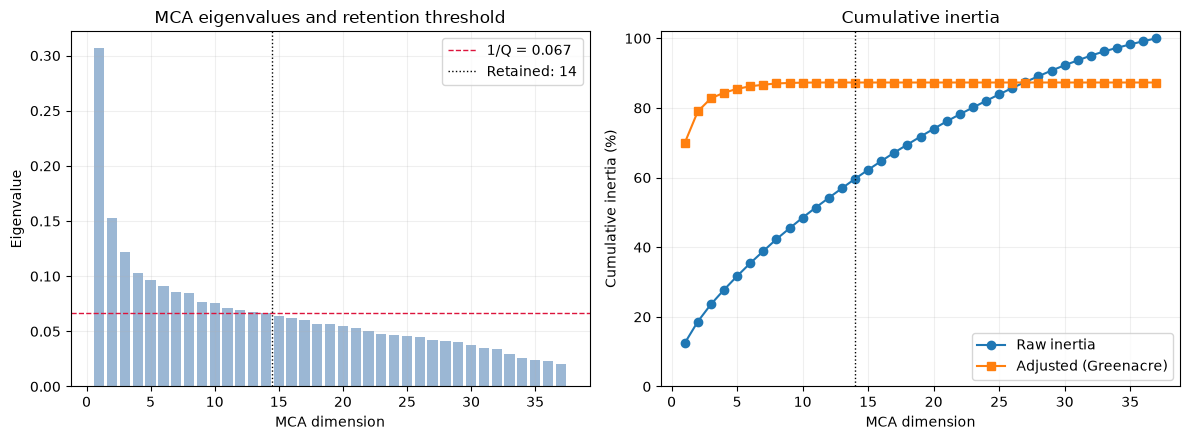

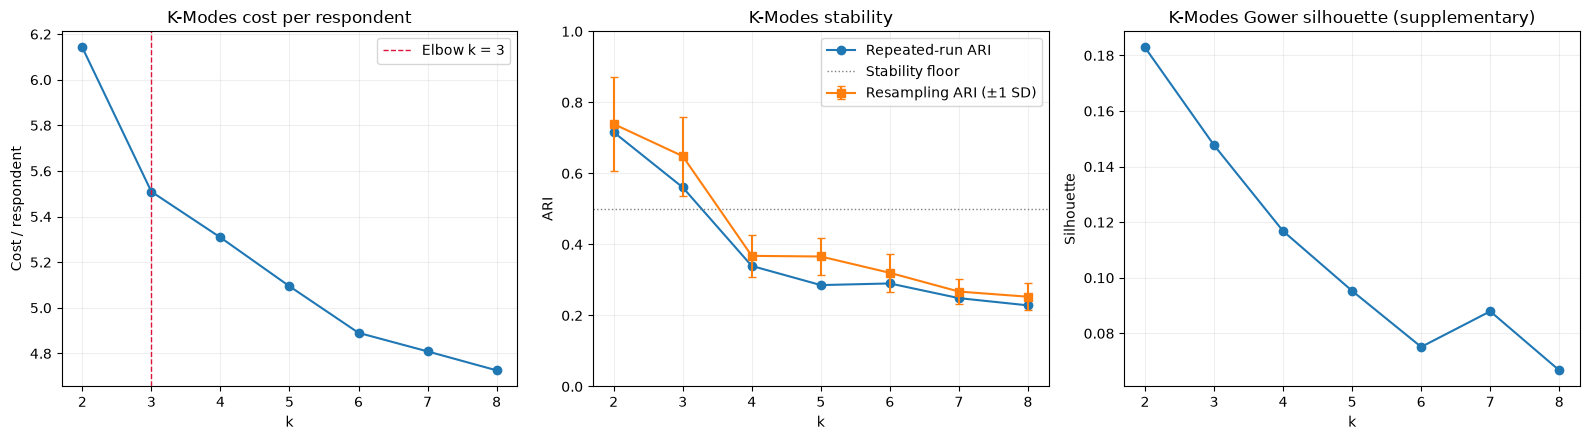

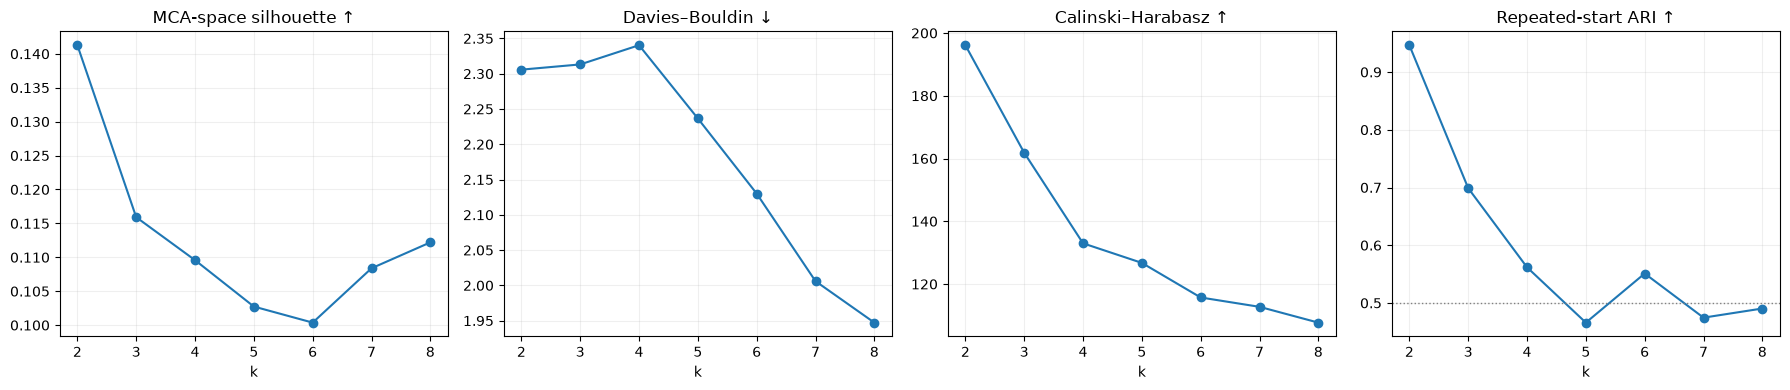

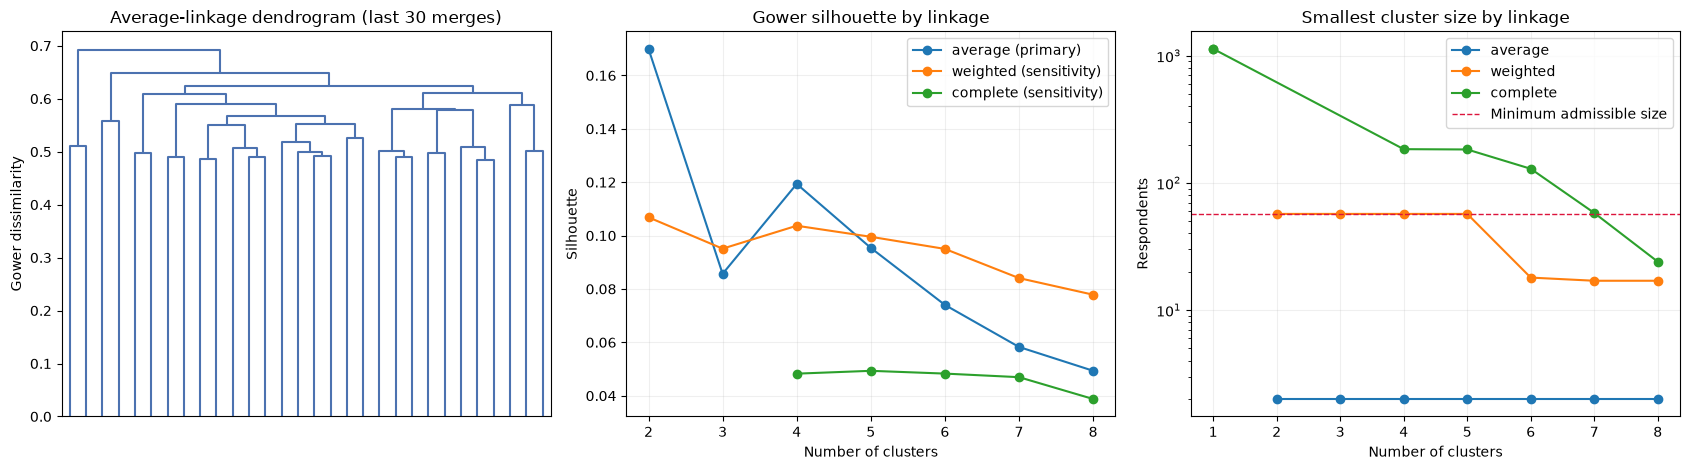

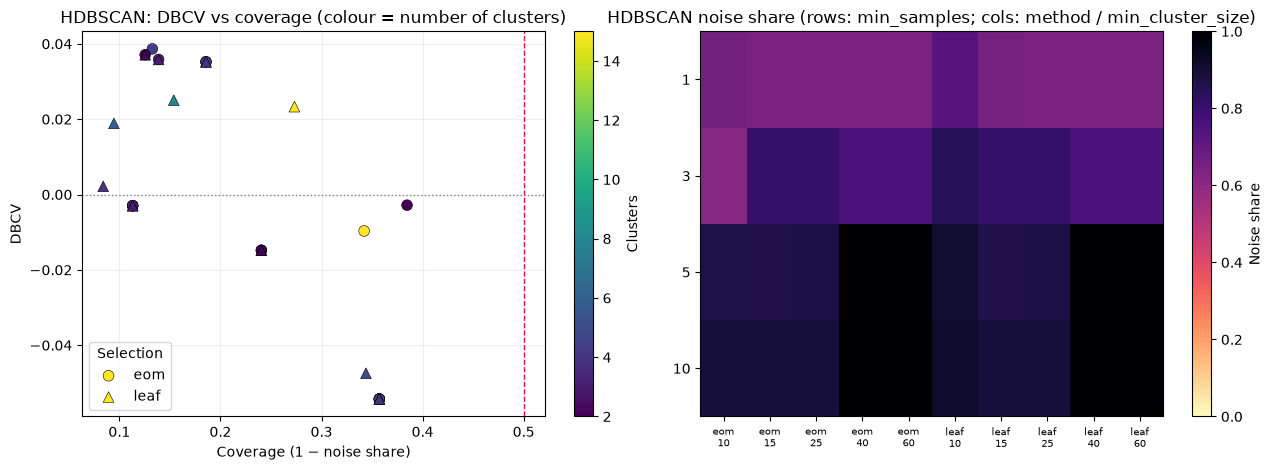

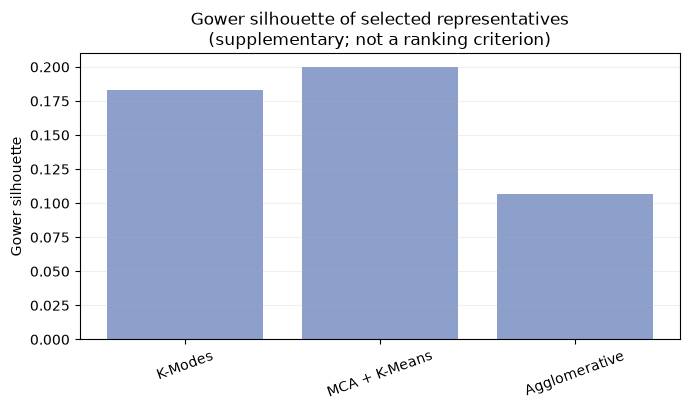

In [13]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=250, bbox_inches="tight")
    plt.show()


# 12.1 MCA dimensionality
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
dims = mca_inertia["dimension"]
axes[0].bar(dims, mca_inertia["eigenvalue"], color="#9bb7d4")
axes[0].axhline(1 / Q, color="crimson", linestyle="--", linewidth=1, label=f"1/Q = {1 / Q:.3f}")
axes[0].axvline(n_components + 0.5, color="black", linestyle=":", linewidth=1, label=f"Retained: {n_components}")
axes[0].set(xlabel="MCA dimension", ylabel="Eigenvalue", title="MCA eigenvalues and retention threshold")
axes[0].legend()
axes[1].plot(dims, mca_inertia["cumulative_inertia_pct"], marker="o", label="Raw inertia")
axes[1].plot(dims, np.cumsum(benzecri_rate) * 100, marker="s", label="Adjusted (Greenacre)")
axes[1].axvline(n_components, color="black", linestyle=":", linewidth=1)
axes[1].set(xlabel="MCA dimension", ylabel="Cumulative inertia (%)", title="Cumulative inertia", ylim=(0, 102))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
save(fig, "mca_dimensionality.png")

# 12.2 K-Modes
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(kmodes_results["k_requested"], kmodes_results["cost_per_respondent"], marker="o")
axes[0].axvline(KMODES_ELBOW_K, color="crimson", linestyle="--", linewidth=1, label=f"Elbow k = {KMODES_ELBOW_K}")
axes[0].set(title="K-Modes cost per respondent", xlabel="k", ylabel="Cost / respondent")
axes[0].legend()
axes[1].plot(kmodes_results["k_requested"], kmodes_results["mean_pairwise_ari"], marker="o", label="Repeated-run ARI")
axes[1].errorbar(kmodes_results["k_requested"], kmodes_results["resampling_ari_mean"],
                 yerr=kmodes_results["resampling_ari_sd"], marker="s", capsize=3, label="Resampling ARI (±1 SD)")
axes[1].axhline(STABILITY_FLOOR, color="grey", linestyle=":", linewidth=1, label="Stability floor")
axes[1].set(title="K-Modes stability", xlabel="k", ylabel="ARI", ylim=(0, 1))
axes[1].legend()
axes[2].plot(kmodes_results["k_requested"], kmodes_results["gower_silhouette"], marker="o")
axes[2].set(title="K-Modes Gower silhouette (supplementary)", xlabel="k", ylabel="Silhouette")
for ax in axes:
    ax.grid(alpha=0.2)
save(fig, "kmodes_cost_stability.png")

# 12.3 MCA + K-Means
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, title in zip(
    axes,
    ["mca_silhouette", "davies_bouldin", "calinski_harabasz", "mean_pairwise_ari"],
    ["MCA-space silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑", "Repeated-start ARI ↑"],
):
    ax.plot(kmeans_results["k_requested"], kmeans_results[col], marker="o")
    ax.set(title=title, xlabel="k")
    ax.grid(alpha=0.2)
axes[3].axhline(STABILITY_FLOOR, color="grey", linestyle=":", linewidth=1)
save(fig, "mca_kmeans_diagnostics.png")

# 12.4 Agglomerative
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
dendrogram(hierarchies["average"], truncate_mode="lastp", p=30, no_labels=True,
           color_threshold=0, above_threshold_color="#4c72b0", ax=axes[0])
axes[0].set(title="Average-linkage dendrogram (last 30 merges)", ylabel="Gower dissimilarity")
for method in LINKAGES:
    sub = agglomerative_results[agglomerative_results["linkage"] == method]
    axes[1].plot(sub["k_actual"], sub["gower_silhouette"], marker="o", label=f"{method} ({LINKAGES[method]})")
    axes[2].plot(sub["k_actual"], sub["smallest_cluster_size"], marker="o", label=method)
axes[1].set(title="Gower silhouette by linkage", xlabel="Number of clusters", ylabel="Silhouette")
axes[2].axhline(MIN_CLUSTER_SIZE, color="crimson", linestyle="--", linewidth=1, label="Minimum admissible size")
axes[2].set(title="Smallest cluster size by linkage", xlabel="Number of clusters", ylabel="Respondents", yscale="log")
for ax in axes[1:]:
    ax.grid(alpha=0.2)
    ax.legend()
save(fig, "agglomerative_diagnostics.png")

# 12.5 HDBSCAN
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for method, marker in zip(HDBSCAN_SELECTION_METHODS, ["o", "^"]):
    sub = hdbscan_results[hdbscan_results["cluster_selection_method"] == method]
    sc = axes[0].scatter(sub["coverage"], sub["dbcv"], c=sub["n_clusters"], cmap="viridis",
                         marker=marker, s=60, edgecolor="black", linewidth=0.4, label=method)
axes[0].axvline(MIN_COVERAGE, color="crimson", linestyle="--", linewidth=1)
axes[0].axhline(DBCV_FLOOR, color="grey", linestyle=":", linewidth=1)
axes[0].set(title="HDBSCAN: DBCV vs coverage (colour = number of clusters)", xlabel="Coverage (1 − noise share)", ylabel="DBCV")
axes[0].legend(title="Selection")
fig.colorbar(sc, ax=axes[0], label="Clusters")
pivot = hdbscan_results.pivot_table(index="min_samples", columns=["cluster_selection_method", "min_cluster_size"],
                                    values="noise_share")
im = axes[1].imshow(pivot.to_numpy(), aspect="auto", cmap="magma_r", vmin=0, vmax=1)
axes[1].set_xticks(range(pivot.shape[1]), [f"{m}\n{c}" for m, c in pivot.columns], fontsize=7)
axes[1].set_yticks(range(pivot.shape[0]), pivot.index)
axes[1].set(title="HDBSCAN noise share (rows: min_samples; cols: method / min_cluster_size)")
fig.colorbar(im, ax=axes[1], label="Noise share")
for ax in axes:
    ax.grid(False) if ax is axes[1] else ax.grid(alpha=0.2)
save(fig, "hdbscan_diagnostics.png")

# 12.6 Supplementary common-space diagnostic (selected representatives only)
if selected:
    fig, ax = plt.subplots(figsize=(7, 4.2))
    names = list(selected)
    values = [selected[m]["row"]["gower_silhouette"] for m in names]
    ax.bar(names, values, color="#8da0cb")
    ax.set(title="Gower silhouette of selected representatives\n(supplementary; not a ranking criterion)",
           ylabel="Gower silhouette")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.2)
    save(fig, "representative_gower_silhouette.png")

## 13. Modelling conclusion and handoff to Notebook 04

The cell below prints the representative configuration per family together with its smallest cluster, native diagnostics and any flags (stability-floor shortfall, sensitivity-linkage fallback, or absence of a qualifying HDBSCAN solution). These flags must be carried into Notebook 04, where the families are compared, profiled and stress-tested for stability.

**Interpretive cautions for Notebook 04**
- Silhouette values from different representations (categorical-matching, MCA-Euclidean, Gower) are not comparable; the Gower silhouette is shared only as a supplementary common-space diagnostic.
- Low silhouettes on 15 categorical survey items indicate overlapping response profiles. Partitions should be described as *summaries of response patterns*, not as discrete respondent types.
- A family without a qualifying representative (typically HDBSCAN when responses are not density-separated) is a result, not a failure to be tuned away.
- Clusters are descriptive. They are not diagnoses, risk scores, or employee-suitability labels.

In [14]:
summary_rows = []
for model_key in ["K-Modes", "MCA + K-Means", "Agglomerative", "HDBSCAN"]:
    if model_key in selected:
        row = selected[model_key]["row"]
        summary_rows.append({
            "model_key": model_key,
            "status": "representative declared",
            "selection_tier": selected[model_key]["tier"],
            "n_clusters": int(row["n_clusters"]),
            "smallest_cluster": int(row["smallest_cluster_size"]),
            "coverage": float(row["coverage"]),
            "gower_silhouette": float(row["gower_silhouette"]),
        })
    else:
        summary_rows.append({"model_key": model_key, "status": "no qualifying representative",
                             "selection_tier": representatives[model_key].get("status")})

handoff = {
    "prepared_respondents": EXPECTED_N,
    "primary_features": EXPECTED_P,
    "candidate_model_keys": list(candidate_label_sets),
    "families_without_representative": [k for k in representatives if k not in candidate_label_sets],
    "representative_configurations": representatives,
    "overall_selection": "deferred_to_notebook_04",
    "candidate_labels_path": (RESULTS_DIR / "osmi_2016_candidate_cluster_labels.csv").relative_to(PROJECT_ROOT).as_posix(),
    "comparison_path": (RESULTS_DIR / "osmi_2016_model_comparison.csv").relative_to(PROJECT_ROOT).as_posix(),
}
display(pd.DataFrame(summary_rows).set_index("model_key"))
display(pd.Series(handoff, name="Notebook 03 handoff").to_frame())

,status,selection_tier,n_clusters,smallest_cluster,coverage,gower_silhouette
model_key,,,,,,
K-Modes,representative declared,admissible and stable,2.0,510.0,1.0,0.182856
MCA + K-Means,representative declared,admissible and stable,2.0,524.0,1.0,0.199978
Agglomerative,representative declared,FALLBACK: no admissible average-linkage cut; b...,2.0,57.0,1.0,0.106843
HDBSCAN,no qualifying representative,no qualifying representative,NaN,NaN,NaN,NaN


,Notebook 03 handoff
prepared_respondents,1131
primary_features,15
candidate_model_keys,"[K-Modes, MCA + K-Means, Agglomerative]"
families_without_representative,[HDBSCAN]
representative_configurations,"{'K-Modes': {'k': 2, 'seed': 2042, 'n_init_per..."
overall_selection,deferred_to_notebook_04
candidate_labels_path,reports/results/data_modelling/osmi_2016_candi...
comparison_path,reports/results/data_modelling/osmi_2016_model...
